# Credit Risk Classification

Predict `loan_status` as a binary classification target

In [80]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier


In [65]:
DATA_PATH = Path("credit_risk_dataset.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Place credit_risk_dataset.csv next to this notebook."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns from {DATA_PATH}.")
display(df.head())

Loaded 32,581 rows and 12 columns from credit_risk_dataset.csv.


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [66]:
print("Column types:")
display(df.dtypes.rename("dtype").to_frame())

print("Missing values by column:")
display(df.isna().sum().rename("missing_values").to_frame())

print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print("Loan-status distribution:")
display(df["loan_status"].value_counts(dropna=False).rename("row_count").to_frame())

Column types:


,dtype
person_age,int64
person_income,int64
person_home_ownership,str
person_emp_length,float64
loan_intent,str
loan_grade,str
loan_amnt,int64
loan_int_rate,float64
loan_status,int64
loan_percent_income,float64


Missing values by column:


,missing_values
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


Exact duplicate rows: 165
Loan-status distribution:


,row_count
loan_status,
0,25473
1,7108


## Clean and validate the modeling data


In [67]:
rows_before = len(df)
df_model = df.drop_duplicates().copy()
duplicate_rows_removed = rows_before - len(df_model)

valid_age = df_model["person_age"].between(18, 100)
valid_employment = (
    df_model["person_emp_length"].isna()
    | (df_model["person_emp_length"] <= df_model["person_age"])
)
valid_loan_amount = df_model["loan_amnt"] > 0
valid_target = df_model["loan_status"].isin([0, 1])
valid_rows = valid_age & valid_employment & valid_loan_amount & valid_target
invalid_rows_removed = int((~valid_rows).sum())
df_model = df_model.loc[valid_rows].reset_index(drop=True)

print(f"Exact duplicates removed: {duplicate_rows_removed:,}")
print(f"Invalid records removed: {invalid_rows_removed:,}")
print(f"Rows retained for modeling: {len(df_model):,}")
print("Feature missing values retained for pipeline imputation:")
display(df_model.drop(columns="loan_status").isna().sum().rename("missing_values").to_frame())

Exact duplicates removed: 165
Invalid records removed: 7
Rows retained for modeling: 32,409
Feature missing values retained for pipeline imputation:


,missing_values
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,887
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3094
loan_percent_income,0
cb_person_default_on_file,0


## Split before preprocessing


In [68]:
X = df_model.drop(columns="loan_status")
y = df_model["loan_status"].astype("int8")

X_train, X_remaining, y_train, y_remaining = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.50,
    random_state=42,
    stratify=y_remaining,
)

print(f"Train: {len(X_train):,} rows ({len(X_train) / len(X):.0%})")
print(f"Validation: {len(X_valid):,} rows ({len(X_valid) / len(X):.0%})")
print(f"Test: {len(X_test):,} rows ({len(X_test) / len(X):.0%})")
print(f"Training positive-class rate: {y_train.mean():.3f}")

Train: 22,686 rows (70%)
Validation: 4,861 rows (15%)
Test: 4,862 rows (15%)
Training positive-class rate: 0.219


In [69]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            numeric_features,
        ),
        (
            "categorical",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            categorical_features,
        ),
    ]
)

print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

Numeric features (7): ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Categorical features (4): ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


## Compare classification models with stratified cross-validation



In [70]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Dummy (majority)": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=1,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=250,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1,
    ),
}

scoring = {
    "roc_auc": "roc_auc",
    "balanced_accuracy": "balanced_accuracy",
    "f1": "f1",
}

In [71]:
cv_rows = []
for model_name, estimator in models.items():
    model_pipeline = Pipeline(
        steps=[("preprocessor", preprocessor), ("model", estimator)]
    )
    fold_scores = cross_validate(
        model_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise",
    )
    cv_rows.append(
        {
            "model": model_name,
            "roc_auc_mean": fold_scores["test_roc_auc"].mean(),
            "roc_auc_std": fold_scores["test_roc_auc"].std(ddof=1),
            "balanced_accuracy_mean": fold_scores["test_balanced_accuracy"].mean(),
            "f1_mean": fold_scores["test_f1"].mean(),
        }
    )

cv_results = pd.DataFrame(cv_rows).sort_values(
    "roc_auc_mean", ascending=False
).reset_index(drop=True)
display(cv_results)

,model,roc_auc_mean,roc_auc_std,balanced_accuracy_mean,f1_mean
0,XGBoost,0.946802,0.008962,0.857430,0.825197
1,Random Forest,0.926835,0.007095,0.849199,0.815136
2,Logistic Regression,0.871003,0.009109,0.800676,0.645899
3,Dummy (majority),0.500000,0.000000,0.500000,0.000000


In [72]:
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBClassifier(
                eval_metric="logloss",
                random_state=42,
                n_jobs=1,
            ),
        ),
    ]
)

parameter_distributions = {
    "model__n_estimators": [200, 350, 500],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.05, 0.1, 0.2],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
}
search_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=parameter_distributions,
    n_iter=8,
    scoring="roc_auc",
    cv=search_cv,
    random_state=42,
    n_jobs=1,
    refit=True,
    error_score="raise",
    verbose=1,
)
xgb_search.fit(X_train, y_train)

print(f"Best training CV ROC-AUC: {xgb_search.best_score_:.4f}")
print(f"Best parameters: {xgb_search.best_params_}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best training CV ROC-AUC: 0.9454
Best parameters: {'model__subsample': 1.0, 'model__n_estimators': 500, 'model__max_depth': 5, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}


In [73]:
best_cv_model_name = cv_results.loc[0, "model"]
best_cv_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", models[best_cv_model_name]),
    ]
)
best_cv_pipeline.fit(X_train, y_train)

candidate_models = {
    f"Best CV: {best_cv_model_name}": best_cv_pipeline,
    "Tuned XGBoost": xgb_search.best_estimator_,
}
validation_rows = []
for model_name, fitted_pipeline in candidate_models.items():
    valid_probabilities = fitted_pipeline.predict_proba(X_valid)[:, 1]
    valid_predictions = (valid_probabilities >= 0.50).astype("int8")
    validation_rows.append(
        {
            "model": model_name,
            "roc_auc": roc_auc_score(y_valid, valid_probabilities),
            "balanced_accuracy_at_0.50": balanced_accuracy_score(
                y_valid, valid_predictions
            ),
            "f1_at_0.50": f1_score(y_valid, valid_predictions, zero_division=0),
        }
    )

validation_results = pd.DataFrame(validation_rows).sort_values(
    "roc_auc", ascending=False
).reset_index(drop=True)
display(validation_results)

selected_model_name = validation_results.loc[0, "model"]
selected_model = candidate_models[selected_model_name]
print(f"Selected using validation ROC-AUC: {selected_model_name}")

,model,roc_auc,balanced_accuracy_at_0.50,f1_at_0.50
0,Tuned XGBoost,0.951816,0.871291,0.841662
1,Best CV: XGBoost,0.951075,0.868430,0.841769


Selected using validation ROC-AUC: Tuned XGBoost


In [74]:
valid_probabilities = selected_model.predict_proba(X_valid)[:, 1]
threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.01):
    valid_predictions = (valid_probabilities >= threshold).astype("int8")
    threshold_rows.append(
        {
            "threshold": round(float(threshold), 2),
            "balanced_accuracy": balanced_accuracy_score(y_valid, valid_predictions),
            "f1": f1_score(y_valid, valid_predictions, zero_division=0),
            "precision": precision_score(y_valid, valid_predictions, zero_division=0),
            "recall": recall_score(y_valid, valid_predictions, zero_division=0),
            "f2": fbeta_score(y_valid, valid_predictions, beta=2, zero_division=0),
        }
    )

threshold_results = pd.DataFrame(threshold_rows).sort_values(
    ["balanced_accuracy", "f1"], ascending=False
).reset_index(drop=True)
selected_threshold = float(threshold_results.loc[0, "threshold"])
display(threshold_results.head(10))
print(f"Validation-selected threshold: {selected_threshold:.2f}")

,threshold,balanced_accuracy,f1,precision,recall,f2
0,0.27,0.886839,0.827389,0.836538,0.818438,0.821995
1,0.23,0.886785,0.814917,0.798016,0.832549,0.825406
2,0.25,0.886690,0.822755,0.822368,0.823142,0.822987
3,0.26,0.886463,0.824586,0.828897,0.820320,0.822021
4,0.24,0.886070,0.817674,0.808648,0.826905,0.823188
5,0.22,0.885827,0.809850,0.785841,0.835372,0.824972
6,0.28,0.885070,0.827190,0.842105,0.812794,0.818492
7,0.29,0.884091,0.829386,0.852883,0.807150,0.815900
8,0.20,0.883590,0.798394,0.759118,0.841957,0.823973
9,0.21,0.883213,0.801080,0.767903,0.837253,0.822399


Validation-selected threshold: 0.27


## Final evaluation on the held-out test set


In [75]:
test_probabilities = selected_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= selected_threshold).astype("int8")

test_metrics = pd.DataFrame(
    [
        {
            "roc_auc": roc_auc_score(y_test, test_probabilities),
            "accuracy": accuracy_score(y_test, test_predictions),
            "balanced_accuracy": balanced_accuracy_score(y_test, test_predictions),
            "precision": precision_score(y_test, test_predictions, zero_division=0),
            "recall": recall_score(y_test, test_predictions, zero_division=0),
            "f1": f1_score(y_test, test_predictions, zero_division=0),
            "threshold": selected_threshold,
        }
    ]
)
display(test_metrics)

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, test_predictions))
print("Classification report:")
print(classification_report(y_test, test_predictions, zero_division=0))

,roc_auc,accuracy,balanced_accuracy,precision,recall,f1,threshold
0,0.949685,0.920609,0.876365,0.832188,0.797742,0.814601,0.27


Confusion matrix (rows = actual, columns = predicted):
[[3628  171]
 [ 215  848]]
Classification report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      3799
           1       0.83      0.80      0.81      1063

    accuracy                           0.92      4862
   macro avg       0.89      0.88      0.88      4862
weighted avg       0.92      0.92      0.92      4862



In [ ]:

probability_summary = pd.Series(test_probabilities).describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
display(probability_summary.to_frame("test_probability"))

print("Unique rounded probability values:", pd.Series(np.round(test_probabilities, 3)).nunique())
print("Minimum probability:", float(test_probabilities.min()))
print("Maximum probability:", float(test_probabilities.max()))


,test_probability
count,4862.000000
mean,0.216609
std,0.342692
min,0.000001
1%,0.000017
5%,0.000172
25%,0.011929
50%,0.050105
75%,0.193287
95%,0.997403


Unique rounded probability values: 570
Minimum probability: 1.0740428706412786e-06
Maximum probability: 0.999998927116394


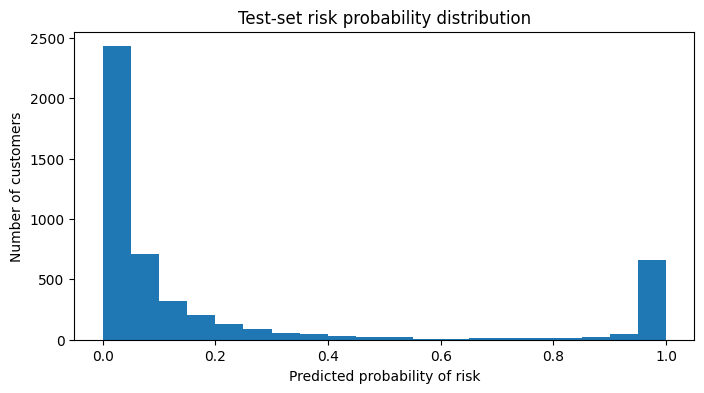

In [ ]:

from matplotlib import pyplot as plt
plt.figure(figsize=(8, 4))
plt.hist(test_probabilities, bins=20)
plt.xlabel("Predicted probability of risk")
plt.ylabel("Number of customers")
plt.title("Test-set risk probability distribution")
plt.show()


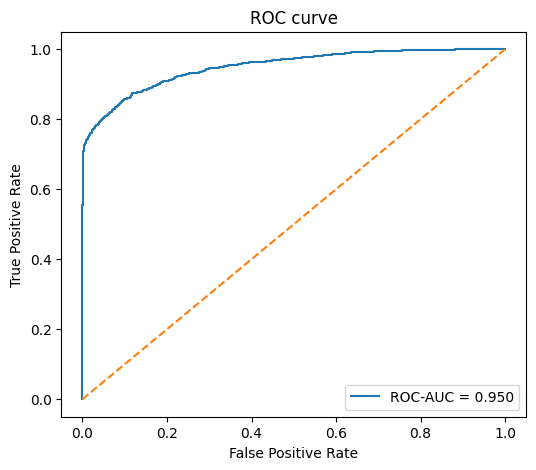

In [ ]:


fpr, tpr, _ = roc_curve(y_test, test_probabilities)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {test_metrics.loc[0, 'roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve")
plt.legend()
plt.show()


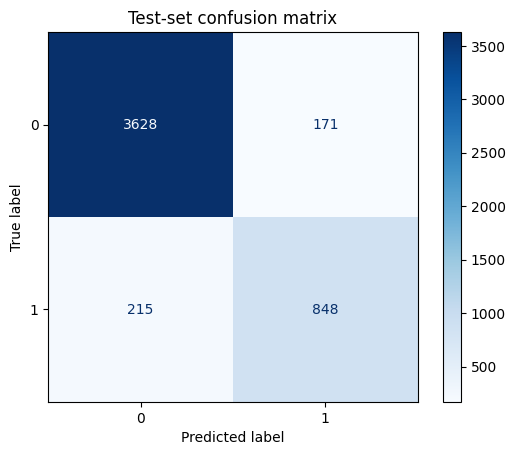

In [83]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    cmap="Blues",
    values_format="d",
)
plt.title("Test-set confusion matrix")
plt.show()

In [84]:
import joblib

model_bundle = {
    "pipeline": selected_model,
    "threshold": selected_threshold,
    "feature_columns": X.columns.tolist(),
    "target_column": "loan_status",
    "selected_model": selected_model_name,
}

output_path = Path("credit_risk_model_bundle.joblib")
joblib.dump(model_bundle, output_path)

print(f"Saved: {output_path.resolve()}")

Saved: E:\AI ML\POJECT\CREDIT RISK\credit_risk_model_bundle.joblib


In [85]:
import joblib

bundle = joblib.load("credit_risk_model_bundle.joblib")

new_data = X_test.iloc[[0]].copy()
new_data = new_data[bundle["feature_columns"]]

risk_probability = bundle["pipeline"].predict_proba(new_data)[:, 1]
predicted_status = (risk_probability >= bundle["threshold"]).astype("int8")

print("Probability of loan_status = 1:", risk_probability[0])
print("Predicted loan_status:", predicted_status[0])

Probability of loan_status = 1: 0.058776937
Predicted loan_status: 0
